***Part 1: Introduction***

In [1]:
print("Hello, there!")


Hello, there!


    column1   column2
0  0.326856  0.946048
1  0.052239  9.596589
2  0.486897  1.756604
3  0.878974  8.989742
4  0.586025  3.506939


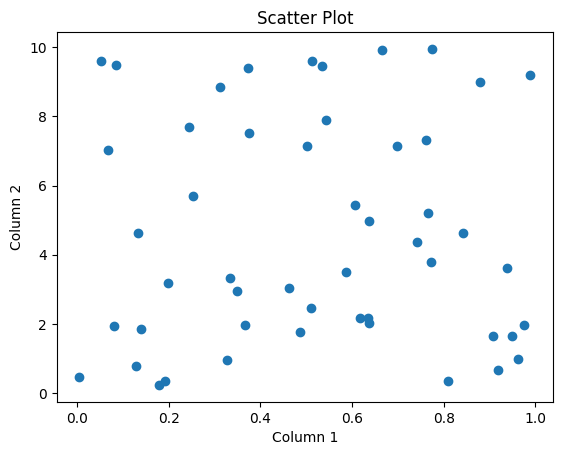

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Create a sample DataFrame
data = pd.DataFrame({
    "column1": np.random.rand(50),  # 50 random values for column1
    "column2": np.random.rand(50) * 10  # 50 random values (multiplied by 10) for column2
})

# Display the first few rows
print(data.head())

# Create a scatter plot
plt.scatter(data["column1"], data["column2"])
plt.xlabel("Column 1")
plt.ylabel("Column 2")
plt.title("Scatter Plot")
plt.show()

***Part 2 - Spam Classification***

**2.1 - Naive Bayes for Spam Detection**

Suppose we have an email with features **F1** and **F2**. We want to determine if this email is spam.

* P(Spam) = 0.3: Prior probability that any email is spam.

* P(Not Spam) = 0.7: Prior probability that any email is not spam.

* P(F1|Spam) = 0.4: Probability of feature F1 given the email is spam.

* P(F2|Spam) = 0.5: Probability of feature F2 given the email is spam.

* P(F1|Not Spam) = 0.2: Probability of feature F1 given the email is not spam.

* P(F2|Not Spam) = 0.3: Probability of feature F2 given the email is not spam.




In [3]:
# Define the given probabilities
P_F1_given_Spam = 0.4   # Probability of feature F1 given Spam
P_F2_given_Spam = 0.5   # Probability of feature F2 given Spam
P_F1_given_Not_Spam = 0.2 # Probability of feature F1 given Not Spam
P_F2_given_Not_Spam = 0.3 # Probability of feature F2 given Not Spam

# Calculate joint probabilities (P(F1, F2 | Spam) and P(F1, F2 | Not Spam))
P_F1_F2_given_Spam = P_F1_given_Spam * P_F2_given_Spam
P_F1_F2_given_Not_Spam = P_F1_given_Not_Spam * P_F2_given_Not_Spam

# Output the results
print(f"P(F1, F2 | Spam) = {P_F1_F2_given_Spam:.4f}")
print(f"P(F1, F2 | Not Spam) = {P_F1_F2_given_Not_Spam:.4f}")


P(F1, F2 | Spam) = 0.2000
P(F1, F2 | Not Spam) = 0.0600


In [4]:
#Step 1 - P(Spam|F1, F2) = (P(F1, F2|Spam) * P(Spam)) / P(F1, F2)
#Step 2 - P(F1, F2) = P(F1, F2|Spam) * P(Spam) + P(F1, F2|Not Spam) * P(Not Spam)
#Step 3 - P(Not Spam|F1, F2) = (P(F1, F2|Not Spam) * P(Not Spam)) / P(F1, F2)
#Step 4 - P(Spam|F1, F2)
#Step 5 - P(Not Spam|F1, F2)
#Step 6 - Compare P(Spam|F1, F2) with P(Not Spam|F1, F2)



In [5]:
# Given probabilities
P_F1_given_Spam = 0.4   # Probability of feature F1 given Spam
P_F2_given_Spam = 0.5   # Probability of feature F2 given Spam
P_F1_given_Not_Spam = 0.2 # Probability of feature F1 given Not Spam
P_F2_given_Not_Spam = 0.3 # Probability of feature F2 given Not Spam
P_Spam = 0.5  # Prior probability of Spam (assuming equal priors)
P_Not_Spam = 0.5  # Prior probability of Not Spam (assuming equal priors)

# Step 1: Calculate P(F1, F2 | Spam)
P_F1_F2_given_Spam = P_F1_given_Spam * P_F2_given_Spam

# Step 2: Calculate P(F1, F2 | Not Spam)
P_F1_F2_given_Not_Spam = P_F1_given_Not_Spam * P_F2_given_Not_Spam

# Step 3: Calculate P(F1, F2)
P_F1_F2 = (P_F1_F2_given_Spam * P_Spam) + (P_F1_F2_given_Not_Spam * P_Not_Spam)

# Step 4: Calculate P(Spam | F1, F2) using Bayes' Theorem
P_Spam_given_F1_F2 = (P_F1_F2_given_Spam * P_Spam) / P_F1_F2

# Step 5: Calculate P(Not Spam | F1, F2) using Bayes' Theorem
P_Not_Spam_given_F1_F2 = (P_F1_F2_given_Not_Spam * P_Not_Spam) / P_F1_F2

# Step 6: Compare the probabilities
print(f"P(Spam | F1, F2): {P_Spam_given_F1_F2}")
print(f"P(Not Spam | F1, F2): {P_Not_Spam_given_F1_F2}")

# If statement to compare and print the result
if P_Spam_given_F1_F2 > P_Not_Spam_given_F1_F2:
    print("The email is more likely to be Spam.")
else:
    print("The email is more likely to be Not Spam.")


P(Spam | F1, F2): 0.7692307692307693
P(Not Spam | F1, F2): 0.23076923076923075
The email is more likely to be Spam.


**2.2 - The Spam Dataset**


In [6]:
import requests
import zipfile
import io

# URL of the dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
# Download the dataset
response = requests.get(url)
if response.status_code == 200:
    print("Download successful")
else:
    print("Failed to download the dataset")

Download successful


In [7]:
# Extract the dataset
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("sms_spam_collection")
    print("Extraction successful")

Extraction successful


In [8]:
import os

# List the extracted files
extracted_files = os.listdir("sms_spam_collection")
print("Extracted files:", extracted_files)

Extracted files: ['SMSSpamCollection', 'readme']


In [9]:
import pandas as pd

# Load the dataset
df = pd.read_csv(
    "sms_spam_collection/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
)

In [10]:
# Display basic information about the dataset
print("-------------------- HEAD --------------------")
print(df.head())
print("-------------------- DESCRIBE --------------------")
print(df.describe())
print("-------------------- INFO --------------------")
print(df.info())

-------------------- HEAD --------------------
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
-------------------- DESCRIBE --------------------
       label                 message
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30
-------------------- INFO --------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [11]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

Missing values:
 label      0
message    0
dtype: int64


In [12]:
# Check for duplicates
print("Duplicate entries:", df.duplicated().sum())

# Remove duplicates if any
df = df.drop_duplicates()

Duplicate entries: 403


**2.3 - Preprocessing the Spam Dataset**

In [13]:
import nltk

# Download the necessary NLTK data files
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

print("=== BEFORE ANY PREPROCESSING ===")
print(df.head(5))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


=== BEFORE ANY PREPROCESSING ===
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [14]:
# Convert all message text to lowercase
df["message"] = df["message"].str.lower()
print("\n=== AFTER LOWERCASING ===")
print(df["message"].head(5))


=== AFTER LOWERCASING ===
0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: object


In [15]:
import re

# Remove non-essential punctuation and numbers, keep useful symbols like $ and !
df["message"] = df["message"].apply(lambda x: re.sub(r"[^a-z\s$!]", "", x))
print("\n=== AFTER REMOVING PUNCTUATION & NUMBERS (except $ and !) ===")
print(df["message"].head(5))


=== AFTER REMOVING PUNCTUATION & NUMBERS (except $ and !) ===
0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in  a wkly comp to win fa cup final...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: message, dtype: object


In [16]:
from nltk.tokenize import word_tokenize

# Split each message into individual tokens
df["message"] = df["message"].apply(word_tokenize)
print("\n=== AFTER TOKENIZATION ===")
print(df["message"].head(5))


=== AFTER TOKENIZATION ===
0    [go, until, jurong, point, crazy, available, o...
1                       [ok, lar, joking, wif, u, oni]
2    [free, entry, in, a, wkly, comp, to, win, fa, ...
3    [u, dun, say, so, early, hor, u, c, already, t...
4    [nah, i, dont, think, he, goes, to, usf, he, l...
Name: message, dtype: object


In [17]:
from nltk.corpus import stopwords

# Define a set of English stop words and remove them from the tokens
stop_words = set(stopwords.words("english"))
df["message"] = df["message"].apply(lambda x: [word for word in x if word not in stop_words])
print("\n=== AFTER REMOVING STOP WORDS ===")
print(df["message"].head(5))


=== AFTER REMOVING STOP WORDS ===
0    [go, jurong, point, crazy, available, bugis, n...
1                       [ok, lar, joking, wif, u, oni]
2    [free, entry, wkly, comp, win, fa, cup, final,...
3        [u, dun, say, early, hor, u, c, already, say]
4    [nah, dont, think, goes, usf, lives, around, t...
Name: message, dtype: object


In [18]:
from nltk.stem import PorterStemmer

# Stem each token to reduce words to their base form
stemmer = PorterStemmer()
df["message"] = df["message"].apply(lambda x: [stemmer.stem(word) for word in x])
print("\n=== AFTER STEMMING ===")
print(df["message"].head(5))


=== AFTER STEMMING ===
0    [go, jurong, point, crazi, avail, bugi, n, gre...
1                         [ok, lar, joke, wif, u, oni]
2    [free, entri, wkli, comp, win, fa, cup, final,...
3        [u, dun, say, earli, hor, u, c, alreadi, say]
4    [nah, dont, think, goe, usf, live, around, tho...
Name: message, dtype: object


In [19]:
# Rejoin tokens into a single string for feature extraction
df["message"] = df["message"].apply(lambda x: " ".join(x))
print("\n=== AFTER JOINING TOKENS BACK INTO STRINGS ===")
print(df["message"].head(5))


=== AFTER JOINING TOKENS BACK INTO STRINGS ===
0    go jurong point crazi avail bugi n great world...
1                                ok lar joke wif u oni
2    free entri wkli comp win fa cup final tkt st m...
3                  u dun say earli hor u c alreadi say
4            nah dont think goe usf live around though
Name: message, dtype: object


**2.4 - Feature Extraction**

In [20]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer with bigrams, min_df, and max_df to focus on relevant terms
vectorizer = CountVectorizer(min_df=1, max_df=0.9, ngram_range=(1, 2))

# Fit and transform the message column
X = vectorizer.fit_transform(df["message"])

# Labels (target variable)
y = df["label"].apply(lambda x: 1 if x == "spam" else 0)  # Converting labels to 1 and 0

**2.5 - Training and Evaluation (Spam Detection)**

In [21]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# Build the pipeline by combining vectorization and classification
pipeline = Pipeline([
    ("vectorizer", vectorizer),
    ("classifier", MultinomialNB())
])

In [22]:
# Define the parameter grid for hyperparameter tuning
param_grid = {
    "classifier__alpha": [0.01, 0.1, 0.15, 0.2, 0.25, 0.5, 0.75, 1.0]
}

# Perform the grid search with 5-fold cross-validation and the F1-score as metric
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1"
)

# Fit the grid search on the full dataset
grid_search.fit(df["message"], y)

# Extract the best model identified by the grid search
best_model = grid_search.best_estimator_
print("Best model parameters:", grid_search.best_params_)

Best model parameters: {'classifier__alpha': 0.25}


In [23]:
# Example SMS messages for evaluation
new_messages = [
    "Congratulations! You've won a $1000 Walmart gift card. Go to http://bit.ly/1234 to claim now.",
    "Hey, are we still meeting up for lunch today?",
    "Urgent! Your account has been compromised. Verify your details here: www.fakebank.com/verify",
    "Reminder: Your appointment is scheduled for tomorrow at 10am.",
    "FREE entry in a weekly competition to win an iPad. Just text WIN to 80085 now!",
]

In [24]:
import numpy as np
import re

# Preprocess function that mirrors the training-time preprocessing
def preprocess_message(message):
    message = message.lower()
    message = re.sub(r"[^a-z\s$!]", "", message)
    tokens = word_tokenize(message)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [stemmer.stem(word) for word in tokens]
    return " ".join(tokens)

In [25]:
# Preprocess and vectorize messages
processed_messages = [preprocess_message(msg) for msg in new_messages]

In [26]:
# Transform preprocessed messages into feature vectors
X_new = best_model.named_steps["vectorizer"].transform(processed_messages)

In [27]:
# Predict with the trained classifier
predictions = best_model.named_steps["classifier"].predict(X_new)
prediction_probabilities = best_model.named_steps["classifier"].predict_proba(X_new)

In [28]:
# Display predictions and probabilities for each evaluated message
for i, msg in enumerate(new_messages):
    prediction = "Spam" if predictions[i] == 1 else "Not-Spam"
    spam_probability = prediction_probabilities[i][1]  # Probability of being spam
    ham_probability = prediction_probabilities[i][0]   # Probability of being not spam

    print(f"Message: {msg}")
    print(f"Prediction: {prediction}")
    print(f"Spam Probability: {spam_probability:.2f}")
    print(f"Not-Spam Probability: {ham_probability:.2f}")
    print("-" * 50)

Message: Congratulations! You've won a $1000 Walmart gift card. Go to http://bit.ly/1234 to claim now.
Prediction: Spam
Spam Probability: 1.00
Not-Spam Probability: 0.00
--------------------------------------------------
Message: Hey, are we still meeting up for lunch today?
Prediction: Not-Spam
Spam Probability: 0.00
Not-Spam Probability: 1.00
--------------------------------------------------
Message: Urgent! Your account has been compromised. Verify your details here: www.fakebank.com/verify
Prediction: Spam
Spam Probability: 0.96
Not-Spam Probability: 0.04
--------------------------------------------------
Message: Reminder: Your appointment is scheduled for tomorrow at 10am.
Prediction: Not-Spam
Spam Probability: 0.00
Not-Spam Probability: 1.00
--------------------------------------------------
Message: FREE entry in a weekly competition to win an iPad. Just text WIN to 80085 now!
Prediction: Spam
Spam Probability: 1.00
Not-Spam Probability: 0.00
----------------------------------

In [29]:
import joblib

# Save the trained model to a file for future use
model_filename = 'spam_detection_model.joblib'
joblib.dump(best_model, model_filename)

print(f"Model saved to {model_filename}")

Model saved to spam_detection_model.joblib


In [30]:
loaded_model = joblib.load(model_filename)
predictions = loaded_model.predict(new_messages)

**2.6 - Model Evaluation (Spam Detection)**

In [31]:
"""
## create your own url via cloud like heruko

import requests
import json

# Define the URL of the API endpoint
url = "http://localhost:8000/api/upload"

# Path to the model file you want to upload
model_file_path = "spam_detection_model.joblib"

# Open the file in binary mode and send the POST request
with open(model_file_path, "rb") as model_file:
    files = {"model": model_file}
    response = requests.post(url, files=files)

# Pretty print the response from the server
print(json.dumps(response.json(), indent=4))

"""

'\n## create your own url via cloud like heruko\n\nimport requests\nimport json\n\n# Define the URL of the API endpoint\nurl = "http://localhost:8000/api/upload"\n\n# Path to the model file you want to upload\nmodel_file_path = "spam_detection_model.joblib"\n\n# Open the file in binary mode and send the POST request\nwith open(model_file_path, "rb") as model_file:\n    files = {"model": model_file}\n    response = requests.post(url, files=files)\n\n# Pretty print the response from the server\nprint(json.dumps(response.json(), indent=4))\n\n'

***Part 3 - Network Anomaly Detection***

**3.1 - Downloading the Dataset**

In [32]:
import requests, zipfile, io

# URL for the NSL-KDD dataset
url = "https://academy.hackthebox.com/storage/modules/292/KDD_dataset.zip"

# Download the zip file and extract its contents
response = requests.get(url)
z = zipfile.ZipFile(io.BytesIO(response.content))
z.extractall('.')  # Extracts to the current directory

BadZipFile: File is not a zip file

**3.2 - Loading the Dataset**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Set the file path to the dataset
file_path = r'KDD+.txt'

# Define the column names corresponding to the NSL-KDD dataset
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login',
    'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'attack', 'level'
]

In [ ]:
# Read the combined NSL-KDD dataset into a DataFrame
df = pd.read_csv(file_path, names=columns)

In [ ]:
print(df.head())

**3.3 - Preprocessing and Splitting the Dataset**

In [ ]:
# Binary classification target
# Maps normal traffic to 0 and any type of attack to 1
df['attack_flag'] = df['attack'].apply(lambda a: 0 if a == 'normal' else 1)

In [ ]:
# Multi-class classification target categories
dos_attacks = ['apache2', 'back', 'land', 'neptune', 'mailbomb', 'pod',
               'processtable', 'smurf', 'teardrop', 'udpstorm', 'worm']
probe_attacks = ['ipsweep', 'mscan', 'nmap', 'portsweep', 'saint', 'satan']
privilege_attacks = ['buffer_overflow', 'loadmdoule', 'perl', 'ps',
                     'rootkit', 'sqlattack', 'xterm']
access_attacks = ['ftp_write', 'guess_passwd', 'http_tunnel', 'imap',
                  'multihop', 'named', 'phf', 'sendmail', 'snmpgetattack',
                  'snmpguess', 'spy', 'warezclient', 'warezmaster',
                  'xclock', 'xsnoop']

def map_attack(attack):
    if attack in dos_attacks:
        return 1
    elif attack in probe_attacks:
        return 2
    elif attack in privilege_attacks:
        return 3
    elif attack in access_attacks:
        return 4
    else:
        return 0

# Assign multi-class category to each row
df['attack_map'] = df['attack'].apply(map_attack)

In [ ]:
# Encoding categorical variables
features_to_encode = ['protocol_type', 'service']
encoded = pd.get_dummies(df[features_to_encode])

In [ ]:
# Numeric features that capture various statistical properties of the traffic
numeric_features = [
    'duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'urgent', 'hot',
    'num_failed_logins', 'num_compromised', 'root_shell', 'su_attempted',
    'num_root', 'num_file_creations', 'num_shells', 'num_access_files',
    'num_outbound_cmds', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate'
]

In [ ]:
# Combine encoded categorical variables and numeric features
train_set = encoded.join(df[numeric_features])

# Multi-class target variable
multi_y = df['attack_map']

In [ ]:
# Split data into training and test sets for multi-class classification
train_X, test_X, train_y, test_y = train_test_split(train_set, multi_y, test_size=0.2, random_state=1337)

In [ ]:
# Further split the training set into separate training and validation sets
multi_train_X, multi_val_X, multi_train_y, multi_val_y = train_test_split(train_X, train_y, test_size=0.3, random_state=1337)

**3.4 - Training and Evaluation (Network Anomaly Detection)**

In [ ]:
# Train RandomForest model for multi-class classification
rf_model_multi = RandomForestClassifier(random_state=1337)
rf_model_multi.fit(multi_train_X, multi_train_y)

In [ ]:
# Predict and evaluate the model on the validation set
multi_predictions = rf_model_multi.predict(multi_val_X)
accuracy = accuracy_score(multi_val_y, multi_predictions)
precision = precision_score(multi_val_y, multi_predictions, average='weighted')
recall = recall_score(multi_val_y, multi_predictions, average='weighted')
f1 = f1_score(multi_val_y, multi_predictions, average='weighted')
print(f"Validation Set Evaluation:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Confusion Matrix for Validation Set
conf_matrix = confusion_matrix(multi_val_y, multi_predictions)
class_labels = ['Normal', 'DoS', 'Probe', 'Privilege', 'Access']
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.title('Network Anomaly Detection - Validation Set')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report for Validation Set
print("Classification Report for Validation Set:")
print(classification_report(multi_val_y, multi_predictions, target_names=class_labels))

In [ ]:
# Final evaluation on the test set
test_multi_predictions = rf_model_multi.predict(test_X)
test_accuracy = accuracy_score(test_y, test_multi_predictions)
test_precision = precision_score(test_y, test_multi_predictions, average='weighted')
test_recall = recall_score(test_y, test_multi_predictions, average='weighted')
test_f1 = f1_score(test_y, test_multi_predictions, average='weighted')
print("\nTest Set Evaluation:")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-Score: {test_f1:.4f}")

# Confusion Matrix for Test Set
test_conf_matrix = confusion_matrix(test_y, test_multi_predictions)
sns.heatmap(test_conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.title('Network Anomaly Detection')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report for Test Set
print("Classification Report for Test Set:")
print(classification_report(test_y, test_multi_predictions, target_names=class_labels))

In [ ]:
import joblib

# Save the trained model to a file
model_filename = 'network_anomaly_detection_model.joblib'
joblib.dump(rf_model_multi, model_filename)

print(f"Model saved to {model_filename}")

**3.5 - Model Evaluation (Network Anomaly Detection)**

In [ ]:
"""
# create your own url via cloud like heruko

import requests
import json

# Define the URL of the API endpoint
url = "http://localhost:8001/api/upload"

# Path to the model file you want to upload
model_file_path = "network_anomaly_detection_model.joblib"

# Open the file in binary mode and send the POST request
with open(model_file_path, "rb") as model_file:
    files = {"model": model_file}
    response = requests.post(url, files=files)

# Pretty print the response from the server
print(json.dumps(response.json(), indent=4))

"""

***Part 4 - Malware Classification***

**4.1 - The Malware Dataset**

In [ ]:
!wget https://www.kaggle.com/api/v1/datasets/download/ikrambenabd/malimg-original -O malimg.zip

In [ ]:
!unzip malimg.zip

In [ ]:
!ls malimg_paper_dataset_imgs

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

DATA_BASE_PATH = "./malimg_paper_dataset_imgs/"

In [ ]:
# compute the class distribution
dist = {}
for mlw_class in os.listdir(DATA_BASE_PATH):
    mlw_dir = os.path.join(DATA_BASE_PATH, mlw_class)
    dist[mlw_class] = len(os.listdir(mlw_dir))

In [ ]:
# plot the class distribution

# HTB Color Palette
htb_green = "#9FEF00"
node_black = "#141D2B"
hacker_grey = "#A4B1CD"

# data
classes = list(dist.keys())
frequencies = list(dist.values())

# plot
plt.figure(facecolor=node_black)
sns.barplot(y=classes, x=frequencies, edgecolor = "black", orient='h', color=htb_green)
plt.title("Malware Class Distribution", color=htb_green)
plt.xlabel("Malware Class Frequency", color=htb_green)
plt.ylabel("Malware Class", color=htb_green)
plt.xticks(color=hacker_grey)
plt.yticks(color=hacker_grey)
ax = plt.gca()
ax.set_facecolor(node_black)
ax.spines['bottom'].set_color(hacker_grey)
ax.spines['top'].set_color(node_black)
ax.spines['right'].set_color(node_black)
ax.spines['left'].set_color(hacker_grey)
plt.show()

**4.2 - Preprocessing the Malware Dataset**

In [ ]:
!pip3 install split-folders

In [ ]:
import splitfolders

DATA_BASE_PATH = "./malimg_paper_dataset_imgs/"
TARGET_BASE_PATH = "./newdata/"

TRAINING_RATIO = 0.8
TEST_RATIO = 1 - TRAINING_RATIO

splitfolders.ratio(input=DATA_BASE_PATH, output=TARGET_BASE_PATH, ratio=(TRAINING_RATIO, 0, TEST_RATIO))

In [ ]:
!ls -la newdata

In [ ]:
!find ./newdata/test/ -type f | wc -l

In [ ]:
!find ./newdata/train/ -type f | wc -l

In [ ]:
!find ./newdata/val/ -type f | wc -l

In [ ]:
from torchvision import transforms

# Define preprocessing transforms
transform = transforms.Compose([
	transforms.Resize((75, 75)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
from torchvision.datasets import ImageFolder
import os

BASE_PATH = "./newdata/"

# Load training and test datasets
train_dataset = ImageFolder(
	root=os.path.join(BASE_PATH, "train"),
    transform=transform
)

test_dataset = ImageFolder(
	root=os.path.join(BASE_PATH, "test"),
    transform=transform
)

In [ ]:
from torch.utils.data import DataLoader

TRAIN_BATCH_SIZE = 1024
TEST_BATCH_SIZE = 1024

# Create data loaders
train_loader = DataLoader(
    train_dataset,
	batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [ ]:
import matplotlib.pyplot as plt

# HTB Color Palette
htb_green = "#9FEF00"
node_black = "#141D2B"
hacker_grey = "#A4B1CD"

# image
sample = next(iter(train_loader))[0][0]

# plot
plt.figure(facecolor=node_black)
plt.imshow(sample.permute(1,2,0))
plt.xticks(color=hacker_grey)
plt.yticks(color=hacker_grey)
ax = plt.gca()
ax.set_facecolor(node_black)
ax.spines['bottom'].set_color(hacker_grey)
ax.spines['top'].set_color(node_black)
ax.spines['right'].set_color(node_black)
ax.spines['left'].set_color(hacker_grey)
ax.tick_params(axis='x', colors=hacker_grey)
ax.tick_params(axis='y', colors=hacker_grey)
plt.show()

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import os

def load_datasets(base_path, train_batch_size, test_batch_size):
    # Define preprocessing transforms
    transform = transforms.Compose([
        transforms.Resize((75, 75)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    # Load training and test datasets
    train_dataset = ImageFolder(
        root=os.path.join(base_path, "train"),
        transform=transform
    )

    test_dataset = ImageFolder(
        root=os.path.join(base_path, "test"),
        transform=transform
    )

    # Create data loaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=train_batch_size,
        shuffle=True,
        num_workers=2
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=test_batch_size,
        shuffle=False,
        num_workers=2
    )

    n_classes = len(train_dataset.classes)
    return train_loader, test_loader, n_classes

**4.3 - The Model**

In [ ]:
import torch.nn as nn
import torchvision.models as models

HIDDEN_LAYER_SIZE = 1000

class MalwareClassifier(nn.Module):
    def __init__(self, n_classes):
        super(MalwareClassifier, self).__init__()
        # Load pretrained ResNet50
        self.resnet = models.resnet50(weights='DEFAULT')

        # Freeze ResNet parameters
        for param in self.resnet.parameters():
            param.requires_grad = False

        # Replace the last fully connected layer
        num_features = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Linear(num_features, HIDDEN_LAYER_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_LAYER_SIZE, n_classes)
        )

    def forward(self, x):
        return self.resnet(x)

In [ ]:
model = MalwareClassifier(25)


In [ ]:
DATA_PATH = "./newdata/"
TRAINING_BATCH_SIZE = 1024
TEST_BATCH_SIZE = 1024

# Load datasets
train_loader, test_loader, n_classes = load_datasets(DATA_PATH, TRAINING_BATCH_SIZE, TEST_BATCH_SIZE)

# Initialize model
model = MalwareClassifier(n_classes)

**4.4 - Training and Evaluation (Malware Image Classification)**

In [ ]:
import torch
import time

def train(model, train_loader, n_epochs, verbose=False):
    model.train()
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters())

    training_data = {"accuracy": [], "loss": []}

    for epoch in range(n_epochs):
        running_loss = 0
        n_total = 0
        n_correct = 0
        checkpoint = time.time() * 1000

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = outputs.max(1)
            n_total += labels.size(0)
            n_correct += predicted.eq(labels).sum().item()
            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        epoch_duration = int(time.time() * 1000 - checkpoint)
        epoch_accuracy = compute_accuracy(n_correct, n_total)

        training_data["accuracy"].append(epoch_accuracy)
        training_data["loss"].append(epoch_loss)

        if verbose:
            print(f"[i] Epoch {epoch+1} of {n_epochs}: Acc: {epoch_accuracy:.2f}% Loss: {epoch_loss:.4f} (Took {epoch_duration} ms).")

    return training_data

In [ ]:
def save_model(model, path):
	model_scripted = torch.jit.script(model)
	model_scripted.save(path)

In [ ]:
def predict(model, test_data):
    model.eval()

    with torch.no_grad():
        output = model(test_data)
        _, predicted = torch.max(output.data, 1)

    return predicted

In [ ]:
def compute_accuracy(n_correct, n_total):
    return round(100 * n_correct / n_total, 2)


def evaluate(model, test_loader):
    model.eval()

    n_correct = 0
    n_total = 0

    with torch.no_grad():
        for data, target in test_loader:
            predicted = predict(model, data)
            n_total += target.size(0)
            n_correct += (predicted == target).sum().item()

    accuracy = compute_accuracy(n_correct, n_total)

    return accuracy


In [ ]:
import matplotlib.pyplot as plt

def plot(data, title, label, xlabel, ylabel):
    # HTB Color Palette
    htb_green = "#9FEF00"
    node_black = "#141D2B"
    hacker_grey = "#A4B1CD"

    # plot
    plt.figure(figsize=(10, 6), facecolor=node_black)
    plt.plot(range(1, len(data)+1), data, label=label, color=htb_green)
    plt.title(title, color=htb_green)
    plt.xlabel(xlabel, color=htb_green)
    plt.ylabel(ylabel, color=htb_green)
    plt.xticks(color=hacker_grey)
    plt.yticks(color=hacker_grey)
    ax = plt.gca()
    ax.set_facecolor(node_black)
    ax.spines['bottom'].set_color(hacker_grey)
    ax.spines['top'].set_color(node_black)
    ax.spines['right'].set_color(node_black)
    ax.spines['left'].set_color(hacker_grey)

    legend = plt.legend(facecolor=node_black, edgecolor=hacker_grey, fontsize=10)
    plt.setp(legend.get_texts(), color=htb_green)

    plt.show()

def plot_training_accuracy(training_data):
    plot(training_data['accuracy'], "Training Accuracy", "Accuracy", "Epoch", "Accuracy (%)")

def plot_training_loss(training_data):
    plot(training_data['loss'], "Training Loss", "Loss", "Epoch", "Loss")

In [ ]:
# data parameters
DATA_PATH = "./newdata/"

# training parameters
N_EPOCHS = 10
TRAINING_BATCH_SIZE = 512
TEST_BATCH_SIZE = 1024

# model parameters
HIDDEN_LAYER_SIZE = 1000
MODEL_FILE = "malware_classifier.pth"


# Load datasets
train_loader, test_loader, n_classes = load_datasets(DATA_PATH, TRAINING_BATCH_SIZE, TEST_BATCH_SIZE)

# Initialize model
model = MalwareClassifier(n_classes)

# Train model
print("[i] Starting Training...")
training_information = train(model, train_loader, N_EPOCHS, verbose=True)

# Save model
save_model(model, MODEL_FILE)

# evaluate model
accuracy = evaluate(model, test_loader)
print(f"[i] Inference accuracy: {accuracy}%.")

# Plot training details
plot_training_accuracy(training_information)
plot_training_loss(training_information)

**4.5 - Model Evaluation (Malware Image Classification)**

In [ ]:
"""
# create your own url using cloud like heruko

import requests
import json

# Define the URL of the API endpoint
url = "http://localhost:8002/api/upload"

# Path to the model file you want to upload
model_file_path = "malware_classifier.pth"

# Open the file in binary mode and send the POST request
with open(model_file_path, "rb") as model_file:
    files = {"model": model_file}
    response = requests.post(url, files=files)

# Pretty print the response from the server
print(json.dumps(response.json(), indent=4))

"""


```

